## Limpieza

In [41]:
import pandas as pd

tempV = []
tempR = []
tempM = []

masas = []				#gramos
voltajes = []			#volts
resistencias = []	#kOhms

with open('.\\datos\\datos.txt', 'r') as file:
	data_raw = file.readlines()

for i in range(5, len(data_raw), 9):
	tempV.append(data_raw[i])
	tempR.append(data_raw[i+1])
	tempM.append(data_raw[i+2])

for t in tempM:
	a = t.replace('Lectura Balanza: ', '')
	b = a.replace(' (crudos/kg segun factor)\n', '')
	masas.append(b)

for t in tempV:
	a = t.replace('Voltaje FSR: ', '')
	b = a.replace(' V\n', '')
	voltajes.append(b)

for t in tempR:
	a = t.replace('Resistencia FSR: ', '')
	b = a.replace(' kOhm\n', '')
	c = b.replace('> 10 MOhm (Circuito abierto / Sin carga)\n','10000')
	resistencias.append(c)

df = pd.DataFrame({
	'Voltaje FSR':voltajes,
	'Resistencia FSR':resistencias,
	'Masa':masas
})

# print(resistencias) 	

# Descomentar en caso de emergencia :)
# df.to_csv("datos.csv", index=False, encoding="utf-8")
df

,Voltaje FSR,Resistencia FSR,Masa
0,0.811,51.66,130.408
1,0.843,49.30,130.505
2,0.843,49.30,130.171
3,1.193,31.91,140.261
4,1.197,31.76,140.401
...,...,...,...
86,0.000,10000,125.114
87,0.018,2831.67,126.934
88,0.098,501.50,126.669
89,0.078,629.38,126.232


# Gráficas

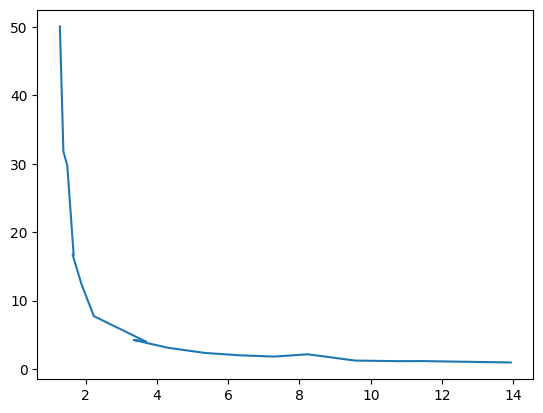

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

data = pd.read_csv('.\\datos\\datos_promedio.csv', sep=',')
# data
plt.plot(data['Masa [g]']*9.81/1000, data['Resistencia FSR [kOhm]'])
plt.show()